# Marketing Channel Performance & First-Purchase Consistency
**Research Question 1 | Data Science Toolbox**

## 1. Environment Setup & Analysis Pipeline
**Decision context.** Compare customer acquisition scale, acquisition cost and estimated lifetime value across marketing channels, then evaluate consistency across first-purchase channels.

**Measurement rules.** One unique customer per row. Mean CAC and median CLV use valid non-negative values. Median CLV/CAC is the median of customer-level ratios with positive CAC. Missing financial values do not remove customers from volume counts. Cross-tab shares are normalized within each first-purchase subgroup. Amounts use unverified source-data currency units; CLV is estimated. Date anomalies are audited without filtering records.

**Source.** [Kaggle dataset](https://www.kaggle.com/datasets/rifatalam3/multi-channel-e-commerce-with-behavioral-metrics/data). Input: the team's cleaned customer file. Source scripts are stored at the project root; generated analytical artifacts are stored in `reports/channel/`.


In [1]:
%pip install -q pandas numpy plotly "dash>=2.11"

Note: you may need to restart the kernel to use updated packages.


In [8]:
from pathlib import Path
import importlib
import pandas as pd
from IPython.display import display, Markdown

DATA_PATH = Path("customer_clean.csv")
OUTPUT_DIR = Path("reports")
assert DATA_PATH.is_file(), f"Input not found: {DATA_PATH.resolve()}"

In [2]:
%%writefile channel_analysis.py
"""Member B: reproducible customer-level channel analysis.
Run: python channel_analysis.py --input data/customer_clean.csv --output reports/channel
"""
from pathlib import Path
import argparse
import hashlib
import json
import numpy as np
import pandas as pd

KEY = "CustomerID"
CHANNEL = "Marketing_Channel"
FIRST = "First_Purchase_Channel"
CLV = "Customer_Lifetime_Value"
CAC = "Customer_Acquisition_Cost"
REQUIRED = [KEY, CHANNEL, FIRST, CLV, CAC]


def load_data(path):
    path = Path(path)
    df = pd.read_csv(path, dtype={KEY: "string"})
    absent = sorted(set(REQUIRED) - set(df.columns))
    if absent:
        raise ValueError(f"Missing required columns: {absent}. Confirm the schema with A.")
    if df.empty:
        raise ValueError("The input file has no customer records.")
    df[KEY] = df[KEY].str.strip()
    if df[KEY].isna().any() or df[KEY].eq("").any():
        raise ValueError("Missing customer IDs: ask A to check them before analysis.")
    if df[KEY].duplicated().any():
        raise ValueError("Repeated customer IDs: confirm the row grain with A; do not silently deduplicate.")
    audit = {"input": str(path.resolve()), "sha256": hashlib.sha256(path.read_bytes()).hexdigest(),
             "rows": len(df), "unique_customers": int(df[KEY].nunique()),
             "missing_raw": {c: int(df[c].isna().sum()) for c in REQUIRED},
             "population": "One row per unique customer; all customers retained in counts.", "missing_customer_id_count": 0, "duplicate_customer_id_count": 0}
    for col in [CHANNEL, FIRST]:
        df[col] = df[col].astype("string").str.strip().replace("", pd.NA).fillna("Unknown")
    for col in [CLV, CAC]:
        numeric = pd.to_numeric(df[col], errors="coerce").astype(float)
        valid = pd.Series(np.isfinite(numeric), index=df.index) & numeric.ge(0)
        audit[f"invalid_or_missing_{col}"] = int((~valid).sum())
        df[col] = numeric.where(valid)
    eligible = df[CAC].gt(0) & df[CLV].notna()
    df["Calculated_CLV_to_CAC"] = (df[CLV] / df[CAC]).where(eligible)
    df["Calculated_CLV_to_CAC"] = df["Calculated_CLV_to_CAC"].replace([np.inf, -np.inf], np.nan)
    audit["zero_CAC"] = int(df[CAC].eq(0).sum())
    audit["excluded_from_ratio"] = int(df["Calculated_CLV_to_CAC"].isna().sum())
    if "CLV_to_CAC_Ratio" in df:
        supplied = pd.to_numeric(df["CLV_to_CAC_Ratio"], errors="coerce")
        comparable = supplied.notna() & df["Calculated_CLV_to_CAC"].notna()
        audit["supplied_ratio_comparable_rows"] = int(comparable.sum())
        audit["supplied_ratio_difference_over_0_011"] = int(
            ((supplied - df["Calculated_CLV_to_CAC"]).abs().gt(.011) & comparable).sum())
    if {"Purchase_Date", "Acquisition_Date"}.issubset(df.columns):
        purchase = pd.to_datetime(df["Purchase_Date"], errors="coerce")
        acquisition = pd.to_datetime(df["Acquisition_Date"], errors="coerce")
        audit["purchase_before_acquisition"] = int(purchase.lt(acquisition).sum())
        audit["unparseable_or_missing_dates"] = int((purchase.isna() | acquisition.isna()).sum())
        audit["date_policy"] = "Flag only; no date-based filtering in this channel comparison. Confirm meanings with A."
    return df, audit


def summarize(df, groups=None):
    groups = groups or [CHANNEL]
    table = df.groupby(groups, dropna=False, observed=True).agg(
        customer_count=(KEY, "nunique"),
        mean_cac=(CAC, "mean"),
        median_clv=(CLV, "median"),
        median_clv_cac=("Calculated_CLV_to_CAC", "median"),
        valid_cac_n=(CAC, "count"),
        valid_clv_n=(CLV, "count"),
        valid_ratio_n=("Calculated_CLV_to_CAC", "count"),
    ).reset_index()
    if FIRST in groups:
        denominator = table.groupby(FIRST)["customer_count"].transform("sum")
    else:
        denominator = table["customer_count"].sum()
    table["customer_share_pct"] = table["customer_count"] / denominator * 100
    return table.sort_values("customer_count", ascending=False).reset_index(drop=True)


def describe(table):
    if table.empty:
        return "No customers match this selection."
    def leaders(metric, highest=True):
        values = table[metric].dropna()
        if values.empty:
            return "unavailable"
        target = values.max() if highest else values.min()
        names = table.loc[table[metric].eq(target), CHANNEL].astype(str).tolist()
        return ", ".join(names) + (f" ({target:,.0f})" if metric == "customer_count" else f" ({target:,.2f})")
    return (f"Largest customer count: {leaders('customer_count')}; "
            f"lowest mean CAC: {leaders('mean_cac', False)}; "
            f"highest median estimated CLV/CAC: {leaders('median_clv_cac')}. "
            "Customer-level comparison within the selected first-purchase scope.")


def executive_summary(df, overall, cross):
    def lead(table, metric, ascending=False):
        values = table[metric].dropna()
        if values.empty:
            return "Unavailable", float("nan")
        best = values.min() if ascending else values.max()
        return ", ".join(table.loc[table[metric].eq(best), CHANNEL]), float(best)
    volume, count = lead(overall, "customer_count")
    cost, mean_cost = lead(overall, "mean_cac", True)
    value, clv = lead(overall, "median_clv")
    efficiency, ratio = lead(overall, "median_clv_cac")
    share = count / len(df) * 100
    lines = ["# Executive Summary",
        f"**Acquisition scale.** {volume} leads customer volume with {count:,.0f} customers ({share:.1f}% of the dataset).",
        f"**Acquisition cost.** {cost} has the lowest mean CAC ({mean_cost:,.2f} source units).",
        f"**Estimated value.** {value} has the highest median estimated CLV ({clv:,.2f} source units); "
        f"{efficiency} has the highest median customer-level CLV/CAC ({ratio:,.2f}x).",
        "## First-purchase consistency"]
    winners = []
    for first, group in cross.groupby(FIRST, observed=True):
        winner, multiple = lead(group, "median_clv_cac")
        winners.append(winner)
        lines.append(f"- **{first}:** {winner} leads median CLV/CAC at {multiple:,.2f}x "
                     f"across a subgroup of {group.customer_count.sum():,.0f} customers.")
    consistency = ("The same CLV/CAC leader appears in every observed first-purchase subgroup."
                   if len(set(winners)) == 1 else
                   "The CLV/CAC leader changes across first-purchase subgroups; the overall leader does not represent every purchase context.")
    lines += [consistency,
        "## Decision implications",
        "Use separate lenses for acquisition scale, cost, and estimated value. Review channels within the relevant first-purchase context before prioritizing further investigation. "
        "These comparisons do not estimate incremental marketing returns or an optimal budget allocation.",
        "## Method and limitations",
        "One row per unique customer. Counts retain all records; financial metrics use valid non-negative values. "
        "CLV/CAC is calculated per customer with positive CAC before taking the group median. "
        "Valid sample counts accompany each metric. Cross-tab customer shares are normalized within each first-purchase subgroup. "
        "CLV is estimated, currency units are unverified, subgroup sizes differ, and channel differences are descriptive. "
        "Date anomalies are logged without removing records; no date-based or active-customer filter is applied."]
    return "\n\n".join(lines)


def run_analysis(input_path, output_dir):
    df, audit = load_data(input_path)
    overall = summarize(df)
    cross = summarize(df, [FIRST, CHANNEL])
    assert int(overall.customer_count.sum()) == len(df)
    assert int(cross.customer_count.sum()) == len(df)
    folder = Path(output_dir)
    folder.mkdir(parents=True, exist_ok=True)
    overall.to_csv(folder / "channel_summary.csv", index=False, encoding="utf-8-sig")
    cross.to_csv(folder / "channel_by_first_purchase.csv", index=False, encoding="utf-8-sig")
    with (folder / "validation_audit.json").open("w", encoding="utf-8") as handle:
        json.dump(audit, handle, ensure_ascii=False, indent=2)
    report = executive_summary(df, overall, cross)
    report += "\n\n## Source record\n\nInput: `" + str(input_path) + "`\n\nSHA256: `" + audit["sha256"] + "`\n"
    report += "\nKaggle source: https://www.kaggle.com/datasets/rifatalam3/multi-channel-e-commerce-with-behavioral-metrics/data\n"
    (folder / "channel_report.md").write_text(report, encoding="utf-8")
    return df, overall, cross, audit


if __name__ == "__main__":
    parser = argparse.ArgumentParser()
    parser.add_argument("--input", default="data/customer_clean.csv")
    parser.add_argument("--output", default="reports/channel")
    args = parser.parse_args()
    _, table, _, _ = run_analysis(args.input, args.output)
    print(table.to_string(index=False))
    print(describe(table))


Overwriting channel_analysis.py


In [9]:
import channel_analysis
importlib.reload(channel_analysis)
from channel_analysis import run_analysis, describe, executive_summary, CHANNEL, FIRST

df, channel_summary, channel_by_first, audit = run_analysis(DATA_PATH, OUTPUT_DIR)
audit_table = pd.DataFrame({"Validation metric": audit.keys(), "Observed value": [str(v) for v in audit.values()]})
display(audit_table)

,Validation metric,Observed value
0,input,/Users/samillelance/Desktop/B_Channel/customer...
1,sha256,9d07d0e29d282dfeaff064b6214ac3914d7f27d465d1bb...
2,rows,50000
3,unique_customers,50000
4,missing_raw,"{'CustomerID': 0, 'Marketing_Channel': 0, 'Fir..."
5,population,One row per unique customer; all customers ret...
6,missing_customer_id_count,0
7,duplicate_customer_id_count,0
8,invalid_or_missing_Customer_Lifetime_Value,0
9,invalid_or_missing_Customer_Acquisition_Cost,0


## 2. Channel Performance Summary
Overall and first-purchase comparisons use identical definitions. `valid_cac_n`, `valid_clv_n` and `valid_ratio_n` identify financial metric denominators. Financial values are rounded for presentation only; calculations retain full precision.

In [10]:
formats = {"customer_count": "{:,.0f}", "mean_cac": "{:,.2f}", "median_clv": "{:,.2f}",
           "median_clv_cac": "{:,.2f}x", "customer_share_pct": "{:.2f}%",
           "valid_cac_n": "{:,.0f}", "valid_clv_n": "{:,.0f}", "valid_ratio_n": "{:,.0f}"}
display(channel_summary.style.format(formats, na_rep="N/A"))
print(describe(channel_summary))

segmented = channel_by_first.sort_values([FIRST, CHANNEL])
display(segmented.style.format(formats, na_rep="N/A"))
for first, group in df.groupby(FIRST, observed=True):
    print(f"{first} | n={len(group):,} | {describe(channel_analysis.summarize(group))}")

,Marketing_Channel,customer_count,mean_cac,median_clv,median_clv_cac,valid_cac_n,valid_clv_n,valid_ratio_n,customer_share_pct
0,Search,"15,034",105.07,"14,758.00",163.71x,"15,034","15,034","15,034",30.07%
1,Social,"12,456",104.66,"14,826.50",167.06x,"12,456","12,456","12,456",24.91%
2,Email,"10,035",105.17,"14,624.00",162.40x,"10,035","10,035","10,035",20.07%
3,Referral,"7,427",104.23,"14,856.00",168.87x,"7,427","7,427","7,427",14.85%
4,Direct,"5,048",104.64,"14,988.50",171.31x,"5,048","5,048","5,048",10.10%


Largest customer count: Search (15,034); lowest mean CAC: Referral (104.23); highest median estimated CLV/CAC: Direct (171.31). Customer-level comparison within the selected first-purchase scope.


,First_Purchase_Channel,Marketing_Channel,customer_count,mean_cac,median_clv,median_clv_cac,valid_cac_n,valid_clv_n,valid_ratio_n,customer_share_pct
14,App,Direct,738,105.02,"13,831.50",155.53x,738,738,738,9.90%
12,App,Email,"1,458",106.04,"13,957.00",154.73x,"1,458","1,458","1,458",19.57%
13,App,Referral,"1,125",103.66,"14,596.00",177.03x,"1,125","1,125","1,125",15.10%
8,App,Search,"2,282",107.71,"14,465.00",153.59x,"2,282","2,282","2,282",30.63%
10,App,Social,"1,848",104.69,"15,681.00",179.57x,"1,848","1,848","1,848",24.80%
7,Online,Direct,"2,540",103.24,"15,233.50",177.11x,"2,540","2,540","2,540",10.04%
2,Online,Email,"5,073",105.38,"14,846.00",163.73x,"5,073","5,073","5,073",20.05%
4,Online,Referral,"3,715",104.58,"15,123.00",172.66x,"3,715","3,715","3,715",14.68%
0,Online,Search,"7,580",103.83,"14,888.50",166.59x,"7,580","7,580","7,580",29.95%
1,Online,Social,"6,398",103.54,"14,633.00",165.87x,"6,398","6,398","6,398",25.28%


App | n=7,451 | Largest customer count: Search (2,282); lowest mean CAC: Referral (103.66); highest median estimated CLV/CAC: Social (179.57). Customer-level comparison within the selected first-purchase scope.
Online | n=25,306 | Largest customer count: Search (7,580); lowest mean CAC: Direct (103.24); highest median estimated CLV/CAC: Direct (177.11). Customer-level comparison within the selected first-purchase scope.
Phone | n=2,393 | Largest customer count: Search (728); lowest mean CAC: Email (100.94); highest median estimated CLV/CAC: Referral (177.28). Customer-level comparison within the selected first-purchase scope.
Store | n=14,850 | Largest customer count: Search (4,444); lowest mean CAC: Referral (104.34); highest median estimated CLV/CAC: Direct (173.13). Customer-level comparison within the selected first-purchase scope.


## 3. Scale, Cost, Value and Purchase Context
The dashboard follows four questions: which channels bring customers; whether acquisition costs differ materially; how cost and estimated value relate; and whether the CLV/CAC leader changes by first-purchase channel.

A share ring, cost-deviation dot plot, customer-sized value map and CLV/CAC matrix answer these questions using different visual encodings. Two supporting exports retain overall ratios and subgroup sample counts. All six figures are saved as standalone interactive HTML files.

The cost dot plot uses the valid-customer mean within the current selection as its benchmark. Value-map axes show the observed range; bubble area represents customers. The context matrix retains all first-purchase groups when a filter is selected. Red highlights the selection's highest median CLV/CAC channel in the first three charts; the matrix uses red intensity for ratio values.

In [11]:
%%writefile channel_app.py
"""Channel performance: scale, cost, value and first-purchase context."""
from pathlib import Path
import argparse
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from dash import Dash, dcc, html, Input, Output
from channel_analysis import load_data, summarize, CHANNEL, FIRST, CAC

BLACK = '#161616'
RED = '#C62828'
GRAY = '#A7A7A7'
ORDER = ['Search', 'Social', 'Email', 'Referral', 'Direct']
FIGURES = ['customer_share', 'cost_comparison', 'value_map', 'first_purchase_ratio']
CSS = """
*{box-sizing:border-box}body{margin:0;background:#F4F3F0;color:#161616;font-family:Arial,Helvetica,sans-serif;font-variant-numeric:tabular-nums}.b-shell{max-width:1440px;margin:0 auto;padding:30px 40px 24px}.b-topline{display:flex;justify-content:space-between;border-bottom:2px solid #161616;padding-bottom:13px;font-size:10px;letter-spacing:1.4px;font-weight:700;text-transform:uppercase}.b-red{color:#C62828}.b-heading{display:flex;justify-content:space-between;align-items:flex-end;gap:30px;padding:27px 0 23px}.b-heading h1{font-size:39px;letter-spacing:-1.8px;margin:0 0 10px;line-height:1.05;font-weight:700}.b-subtitle{font-size:13px;color:#666;margin:0;line-height:1.6}.b-filter{min-width:235px;width:250px}.b-filter label{display:block;font-size:10px;letter-spacing:1px;font-weight:700;text-transform:uppercase;margin-bottom:8px}.b-hero{background:#161616;color:white;padding:25px 28px;display:grid;grid-template-columns:1.2fr 1fr;gap:35px;align-items:center}.b-hero h2{font-size:26px;letter-spacing:-.6px;font-weight:500;line-height:1.25;margin:0}.b-hero p{font-size:12px;color:#D0D0D0;margin:0;line-height:1.8}.b-kpis{display:grid;grid-template-columns:repeat(4,minmax(0,1fr));border-bottom:1px solid #CCC;margin:0 0 24px}.b-kpi{padding:22px 18px 20px 0}.b-kpi+.b-kpi{padding-left:24px;border-left:1px solid #D8D8D8}.b-label{font-size:10px;color:#666;text-transform:uppercase;letter-spacing:1px}.b-number{font-size:30px;letter-spacing:-1px;font-weight:700;margin:8px 0 5px}.b-detail{font-size:11px;color:#777;line-height:1.5}.b-legend{font-size:11px;color:#666;display:flex;gap:7px;align-items:center;margin:0 0 13px}.b-dot{width:7px;height:7px;background:#C62828;border-radius:50%;display:inline-block}.b-grid{display:grid;grid-template-columns:1fr 1.2fr;gap:18px}.b-panel{background:white;border:1px solid #DDDCDA;overflow:hidden}.b-panel-head{padding:19px 21px 0}.b-panel-head h3{font-size:16px;letter-spacing:-.3px;font-weight:700;margin:0 0 6px}.b-panel-head p{font-size:11px;line-height:1.5;color:#777;margin:0}.b-panel-foot{font-size:10px;color:#777;line-height:1.6;padding:0 21px 17px;min-height:46px}.b-index{color:#C62828;font-size:10px;margin-right:8px}.b-table-section{margin-top:25px}.b-table-heading{display:flex;justify-content:space-between;align-items:baseline;padding:0 0 12px;border-bottom:2px solid #161616}.b-table-heading h3{font-size:16px;margin:0}.b-table-wrap{overflow-x:auto}.b-table{width:100%;border-collapse:collapse;white-space:nowrap;font-size:11px}.b-table th{font-size:9px;letter-spacing:.7px;text-transform:uppercase;font-weight:500;color:#777;padding:13px 10px;text-align:right;border-bottom:1px solid #CCC}.b-table td{padding:13px 10px;text-align:right;border-bottom:1px solid #DDD}.b-table td:first-child,.b-table th:first-child{text-align:left;padding-left:0}.b-table tr.b-focus td:first-child{color:#C62828;font-weight:700}.b-table tbody tr:hover{background:#FFF}.b-notes{font-size:10px;line-height:1.8;color:#777;max-width:1100px;margin:17px 0 0}.b-footer{font-size:9px;letter-spacing:1px;text-transform:uppercase;color:#888;border-top:1px solid #CCC;margin-top:20px;padding-top:12px;display:flex;justify-content:space-between}
@media(max-width:1000px){.b-shell{padding:25px}.b-grid{grid-template-columns:1fr 1fr}.b-heading h1{font-size:33px}.b-hero h2{font-size:23px}}
@media(max-width:720px){.b-shell{padding:16px}.b-heading{align-items:stretch;flex-direction:column;gap:18px}.b-filter{width:100%}.b-grid,.b-hero{grid-template-columns:1fr}.b-hero{gap:14px}.b-kpis{grid-template-columns:repeat(2,1fr)}.b-kpi:nth-child(3){padding-left:0;border-left:none}.b-kpi{border-bottom:1px solid #DDD}.b-heading h1{font-size:31px}.b-topline{font-size:8px}.b-number{font-size:26px}}
"""


def base(fig, height=310, **overrides):
    settings = dict(template='plotly_white',height=height,paper_bgcolor='white',plot_bgcolor='white',
        font=dict(family='Arial, sans-serif',size=11,color='#555'),
        margin=dict(l=65,r=30,t=35,b=45),showlegend=False,
        hoverlabel=dict(bgcolor=BLACK,font_color='white',bordercolor=BLACK))
    settings.update(overrides)
    fig.update_layout(**settings)
    return fig


def leader(table, metric, lowest=False):
    valid=table[metric].dropna()
    if valid.empty:return 'Unavailable',None
    target=valid.min() if lowest else valid.max()
    return ', '.join(table.loc[table[metric].eq(target),CHANNEL]),float(target)


def share_figure(table, focus):
    ordered=table.sort_values('customer_count',ascending=False)
    colors=[RED if c==focus else color for c,color in zip(ordered[CHANNEL],['#252525','#606060','#949494','#BEBEBE','#DFDFDF'])]
    fig=go.Figure(go.Pie(labels=ordered[CHANNEL],values=ordered.customer_count,
        hole=.73,sort=False,direction='clockwise',rotation=90,
        marker=dict(colors=colors,line=dict(color='white',width=3)),
        textinfo='none',hovertemplate='%{label}<br>%{value:,} customers<br>%{percent}<extra></extra>'))
    count=int(ordered.customer_count.sum())
    fig.add_annotation(text=f'<b>{count:,}</b><br><span style="font-size:10px;color:#777">CUSTOMERS</span>',
        x=.40,y=.5,xref='paper',yref='paper',showarrow=False,font=dict(size=25,color=BLACK))
    fig.update_traces(domain=dict(x=[0,.8],y=[0,1]))
    return base(fig,showlegend=True,legend=dict(x=.79,y=.5,yanchor='middle',font=dict(size=11),traceorder='normal'),
        margin=dict(l=10,r=10,t=20,b=20))


def cost_figure(table, benchmark, focus):
    table=table.dropna(subset=['mean_cac']).sort_values('mean_cac').copy()
    if table.empty or pd.isna(benchmark):return base(go.Figure())
    if benchmark==0:
        x=table.mean_cac
        x_title='Mean CAC · source units'
        ref=0
    else:
        x=(table.mean_cac/benchmark-1)*100
        x_title='Difference from selected-customer mean (%)'
        ref=0
    fig=go.Figure(go.Scatter(x=x,y=table[CHANNEL],mode='markers+text',
        text=[f'{v:,.2f}' for v in table.mean_cac],textposition='top center',
        textfont=dict(size=11,color=BLACK),marker=dict(size=11,color=[RED if c==focus else BLACK for c in table[CHANNEL]]),
        customdata=table[['mean_cac','valid_cac_n']].values,
        hovertemplate='%{y}<br>Mean CAC: %{customdata[0]:,.2f}<br>Valid customers: %{customdata[1]:,.0f}<extra></extra>'))
    fig.add_vline(x=ref,line_dash='dot',line_color='#AAA',line_width=1)
    limit=max(float(np.abs(x).max())*1.6,.5)
    fig.update_xaxes(title=x_title,range=[-limit,limit],ticksuffix='%' if benchmark else '',gridcolor='#EEE',zeroline=False)
    fig.update_yaxes(autorange='reversed',showgrid=False,tickfont=dict(color=BLACK))
    return base(fig,margin=dict(l=70,r=40,t=30,b=65))


def value_figure(table, focus):
    table=table.dropna(subset=['mean_cac','median_clv']).copy()
    if table.empty:return base(go.Figure())
    fig=go.Figure(go.Scatter(x=table.mean_cac,y=table.median_clv,mode='markers+text',
        text=table[CHANNEL],textposition='top center',textfont=dict(size=11,color=BLACK),
        marker=dict(size=table.customer_count,sizemode='area',sizeref=2*table.customer_count.max()/42**2,sizemin=8,
            color=[RED if c==focus else '#888' for c in table[CHANNEL]],opacity=.82,line=dict(color='white',width=1.5)),
        customdata=table[[CHANNEL,'customer_count','median_clv_cac','valid_clv_n','valid_cac_n','valid_ratio_n']].values,
        hovertemplate='%{customdata[0]}<br>Mean CAC: %{x:,.2f}<br>Median estimated CLV: %{y:,.2f}'
        '<br>Customers: %{customdata[1]:,}<br>Median CLV/CAC: %{customdata[2]:,.2f}x'
        '<br>Valid CLV / CAC / ratio: %{customdata[3]} / %{customdata[4]} / %{customdata[5]}<extra></extra>'))
    for column,axis in [('mean_cac','x'),('median_clv','y')]:
        lo,hi=table[column].min(),table[column].max();pad=max((hi-lo)*.25,abs(hi)*.0005, .1)
        kwargs=dict(range=[lo-pad,hi+pad],gridcolor='#EEE',zeroline=False)
        (fig.update_xaxes if axis=='x' else fig.update_yaxes)(**kwargs)
    fig.update_xaxes(title='Mean CAC · source units',tickformat=',.1f')
    fig.update_yaxes(title='Median estimated CLV · source units',tickformat=',.0f')
    return base(fig,margin=dict(l=80,r=35,t=30,b=55))


def ratio_heatmap(cross, selected='__ALL__'):
    rows=[c for c in ['Online','Store','App','Phone'] if c in set(cross[FIRST])]
    rows += sorted(set(cross[FIRST])-set(rows))
    cols=[c for c in ORDER if c in set(cross[CHANNEL])]+sorted(set(cross[CHANNEL])-set(ORDER))
    values=cross.pivot(index=FIRST,columns=CHANNEL,values='median_clv_cac').reindex(index=rows,columns=cols)
    counts=cross.pivot(index=FIRST,columns=CHANNEL,values='customer_count').reindex(index=rows,columns=cols)
    valid=cross.pivot(index=FIRST,columns=CHANNEL,values='valid_ratio_n').reindex(index=rows,columns=cols)
    custom=np.stack([counts.values,valid.values],axis=-1)
    text=np.array([[f'{v:.1f}x' if pd.notna(v) else 'N/A' for v in row] for row in values.values])
    fig=go.Figure(go.Heatmap(x=cols,y=rows,z=values.values,text=text,texttemplate='%{text}',
        customdata=custom,colorscale=[[0,'#FCF6F5'],[.5,'#E4A4A0'],[1,'#B51F24']],
        xgap=4,ygap=4,colorbar=dict(title='CLV/CAC',thickness=8,len=.7,tickfont=dict(size=9)),
        hovertemplate='%{y} / %{x}<br>Median CLV/CAC: %{z:,.2f}x<br>Customers: %{customdata[0]:,.0f}'
        '<br>Valid ratios: %{customdata[1]:,.0f}<extra></extra>'))
    if selected in rows:
        i=rows.index(selected)
        fig.add_shape(type='rect',xref='x',yref='y',x0=-.5,x1=len(cols)-.5,y0=i-.5,y1=i+.5,
            line=dict(color=BLACK,width=2),fillcolor='rgba(0,0,0,0)')
    fig.update_xaxes(side='top',showgrid=False)
    fig.update_yaxes(autorange='reversed',showgrid=False)
    return base(fig,margin=dict(l=65,r=65,t=35,b=20))


def build_views(df, selected, first):
    table=summarize(selected)
    focus,_=leader(table,'median_clv_cac')
    cross=summarize(df,[FIRST,CHANNEL])
    return {
        'customer_share':share_figure(table,focus),
        'cost_comparison':cost_figure(table,selected[CAC].mean(),focus),
        'value_map':value_figure(table,focus),
        'first_purchase_ratio':ratio_heatmap(cross,first),
    }


def export_figures(overall,cross,output_dir,df=None):
    if df is None:raise ValueError('Pass the validated customer DataFrame as df= to compute customer-weighted cost benchmarks.')
    figures=build_views(df,df,'__ALL__')
    # A separate dot plot preserves exact overall ratio comparisons for presentation.
    ordered=overall.sort_values('median_clv_cac')
    fig=go.Figure(go.Scatter(x=ordered.median_clv_cac,y=ordered[CHANNEL],mode='markers+text',
        text=[f'{v:.2f}x' if pd.notna(v) else 'N/A' for v in ordered.median_clv_cac],textposition='top center',
        marker=dict(color=[RED if v==ordered.median_clv_cac.max() else BLACK for v in ordered.median_clv_cac],size=10)))
    fig.update_xaxes(title='Median customer-level CLV/CAC (x)',gridcolor='#EEE');fig.update_yaxes(showgrid=False)
    figures['overall_ratio_detail']=base(fig)
    counts=cross.pivot(index=FIRST,columns=CHANNEL,values='customer_count')
    fig=go.Figure(go.Heatmap(x=list(counts.columns),y=list(counts.index),z=counts.values,
        text=counts.values,texttemplate='%{text:,.0f}',colorscale=[[0,'#F5F5F5'],[1,'#333']],showscale=False))
    figures['sample_coverage']=base(fig)
    folder=Path(output_dir);folder.mkdir(parents=True,exist_ok=True)
    titles={'customer_share':'Customer share','cost_comparison':'Acquisition cost comparison',
        'value_map':'Acquisition cost and estimated value','first_purchase_ratio':'First-purchase CLV/CAC',
        'overall_ratio_detail':'Overall CLV/CAC','sample_coverage':'Customer counts by subgroup'}
    for name,figure in figures.items():
        exported=go.Figure(figure).update_layout(title=dict(text=titles[name],font=dict(size=16,color=BLACK)),margin_t=65)
        exported.write_html(folder/f'{name}.html',include_plotlyjs=True,config={'displayModeBar':False,'responsive':True})
    return figures


def channel_layout(df):
    options=[v for v in ['Online','Store','App','Phone'] if v in set(df[FIRST])]
    options+=sorted(set(df[FIRST])-set(options))
    panels=[
        ('01','Who brings the customers?','Share of customers in the selected first-purchase group.','customer_share',
            'Hover for exact counts and shares. Slice size represents customers, not marketing spend.'),
        ('02','How different are acquisition costs?','Dots show distance from the mean; labels show the actual cost.','cost_comparison',
            'Zero = mean CAC across selected customers. Differences are shown in percent, not currency units.'),
        ('03','Where do cost and value meet?','Higher = greater estimated value. Further left = lower acquisition cost.','value_map',
            'Bubble area = customers. Axes show the observed range. Channel CLV medians and CAC means are separate summaries.'),
        ('04','Does the leader change at first purchase?','Median customer-level CLV/CAC for each purchase context.','first_purchase_ratio',
            'Darker red = higher ratio. All contexts stay visible; a black outline marks the selected row. Hover for sample sizes.'),
    ]
    return html.Main([
        html.Div([html.Span('E-commerce / Channel analysis'),html.Span('RQ1',className='b-red')],className='b-topline'),
        html.Header([html.Div([html.H1('Channel performance'),
            html.P('Customer volume, acquisition cost and estimated value.',className='b-subtitle')]),
            html.Div([html.Label('First-purchase channel',htmlFor='b-first-purchase'),
                dcc.Dropdown(id='b-first-purchase',options=[{'label':'All customers','value':'__ALL__'}]+[{'label':v,'value':v} for v in options],
                    value='__ALL__',clearable=False)],className='b-filter')],className='b-heading'),
        html.Div(id='b-story',className='b-hero'),html.Div(id='b-kpis',className='b-kpis'),
        html.Div([html.Span(className='b-dot'),html.Span(id='b-focus-note')],className='b-legend'),
        html.Div([html.Section([html.Div([html.H3([html.Span(number,className='b-index'),title]),html.P(subtitle)],className='b-panel-head'),
            dcc.Graph(id=f'b-chart-{key}',style={'height':'310px'},config={'displayModeBar':False,'responsive':True}),
            html.Div(note,className='b-panel-foot')],className='b-panel') for number,title,subtitle,key,note in panels],className='b-grid'),
        html.Section([html.Div([html.H3('The numbers behind the view'),html.Span(id='b-scope',className='b-detail')],className='b-table-heading'),
            html.Div(id='b-table',className='b-table-wrap')],className='b-table-section'),
        html.P('Basis: one record per customer. CLV is an estimate; currency units are unverified. Financial metrics exclude invalid values; '
            'ratios also exclude zero CAC. Valid sample sizes are shown below. These comparisons do not establish incremental marketing returns.',className='b-notes'),
        html.Footer([html.Span('Data Science Toolbox'),html.Span('Marketing channels / First-purchase context')],className='b-footer')
    ],className='b-shell')


def render_selection(df, first):
    selected=df if first=='__ALL__' else df.loc[df[FIRST].eq(first)]
    table=summarize(selected)
    volume,count=leader(table,'customer_count');focus,ratio=leader(table,'median_clv_cac')
    cost,lowest=leader(table,'mean_cac',True);_,highest=leader(table,'mean_cac')
    mean=selected[CAC].mean()
    spread=(highest-lowest)/mean*100 if lowest is not None and pd.notna(mean) and mean else None
    scope='All customers' if first=='__ALL__' else first
    share=count/len(selected)*100 if count and len(selected) else 0
    if selected.empty:
        story=[html.H2('No customers in this selection.'),html.P('Choose another first-purchase channel.')]
    else:
        story=[html.H2([f'{volume} brings the volume.',html.Br(),f'{focus} leads on value-to-cost.']),
            html.P(f'{volume} accounts for {share:.1f}% of {scope.lower() if first=="__ALL__" else scope+" customers"}. '
                f'{focus} has the highest median estimated CLV/CAC at {ratio:.1f}x. '
                +(f'The full range of mean acquisition costs spans just {spread:.1f}% of the customer mean.' if spread is not None else ''))]
    def number(v,suffix=''):return 'N/A' if v is None or pd.isna(v) else f'{v:,.1f}{suffix}'
    def card(label,value,detail,red=False):
        return html.Div([html.Div(label,className='b-label'),html.Div(value,className='b-number'+(' b-red' if red else '')),
            html.Div(detail,className='b-detail')],className='b-kpi')
    cards=[card('Customers',f'{len(selected):,}',f'{len(selected)/len(df)*100:.1f}% of the full dataset'),
        card('Mean acquisition cost',number(mean),'Source-data units'),
        card('Median estimated CLV',number(selected['Customer_Lifetime_Value'].median()),'Source-data units'),
        card('Highest median CLV/CAC',number(ratio,'x'),focus,True)]
    fields=[CHANNEL,'customer_count','customer_share_pct','mean_cac','median_clv','median_clv_cac','valid_cac_n','valid_clv_n','valid_ratio_n']
    headers=['Channel','Customers','Share','Mean CAC','Median CLV','Median CLV/CAC','CAC n','CLV n','Ratio n']
    def cell(value,field):
        if pd.isna(value):return 'N/A'
        if field==CHANNEL:return str(value)
        if field.endswith('_n') or field=='customer_count':return f'{value:,.0f}'
        return f'{value:,.2f}'+('x' if field=='median_clv_cac' else '%' if field=='customer_share_pct' else '')
    data_table=html.Table([html.Thead(html.Tr([html.Th(x) for x in headers])),
        html.Tbody([html.Tr([html.Td(cell(row[f],f)) for f in fields],className='b-focus' if row[CHANNEL]==focus else '')
            for _,row in table.iterrows()])],className='b-table')
    views=build_views(df,selected,first)
    return story,cards,f'Red highlights {focus}, the CLV/CAC leader in this selection. The matrix uses a value scale.',f'{scope} · {len(selected):,} customers',*[views[key] for key in FIGURES],data_table


def register_channel_callbacks(app,df):
    @app.callback(Output('b-story','children'),Output('b-kpis','children'),Output('b-focus-note','children'),Output('b-scope','children'),
        *[Output(f'b-chart-{key}','figure') for key in FIGURES],Output('b-table','children'),Input('b-first-purchase','value'))
    def update(first):return render_selection(df,first)
    return update


def build_app(input_path):
    df,_=load_data(input_path)
    app=Dash(__name__);app.title='Channel performance'
    app.index_string=app.index_string.replace('</head>','<style>'+CSS+'</style></head>')
    app.layout=channel_layout(df);register_channel_callbacks(app,df)
    return app


if __name__=='__main__':
    parser=argparse.ArgumentParser();parser.add_argument('--input',default='data/customer_clean.csv');parser.add_argument('--port',type=int,default=8050)
    args=parser.parse_args();build_app(args.input).run(debug=False,port=args.port)

Overwriting channel_app.py


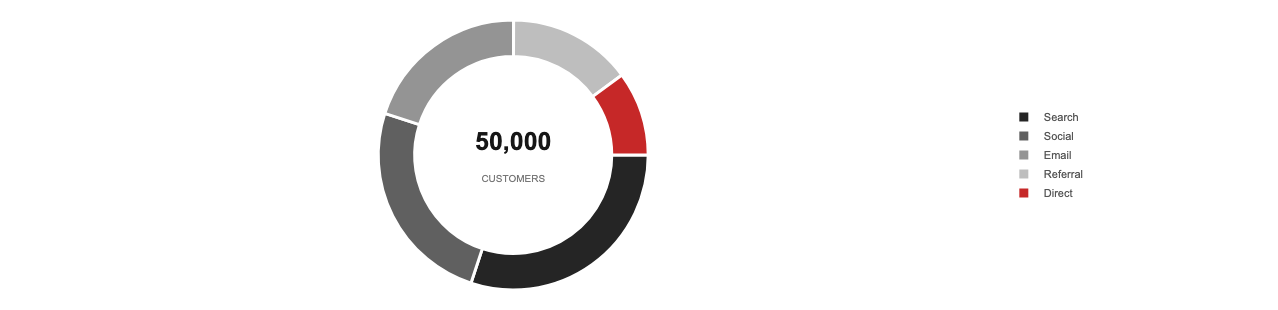

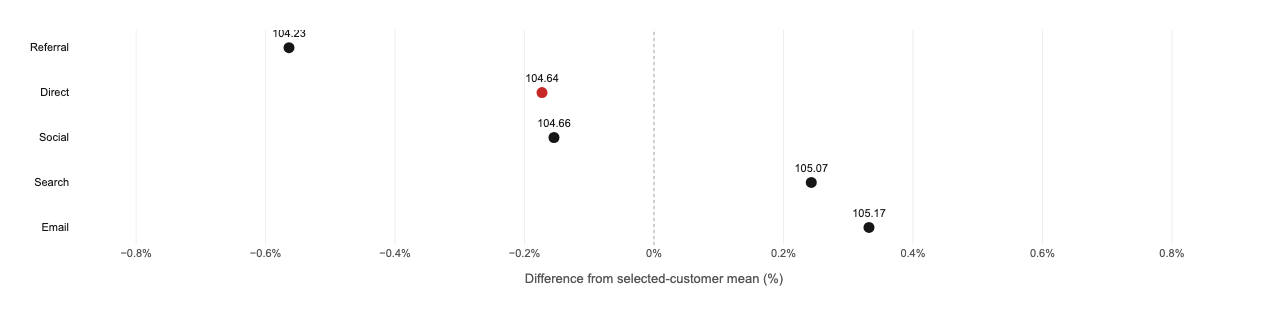

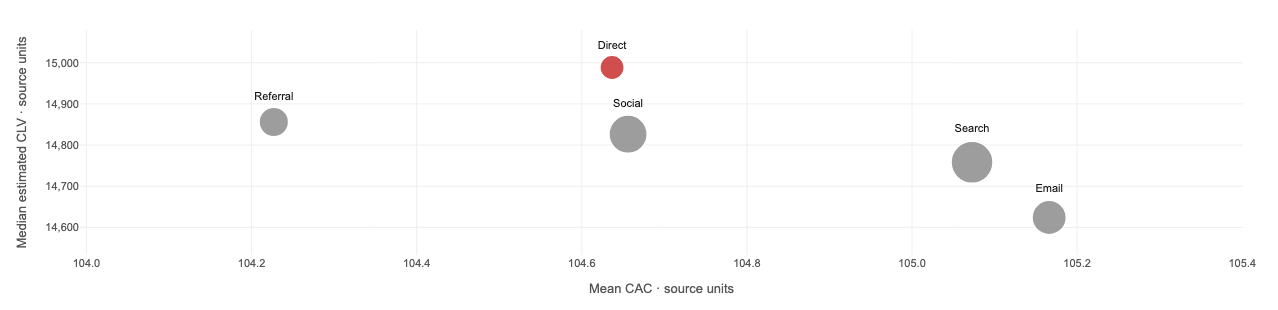

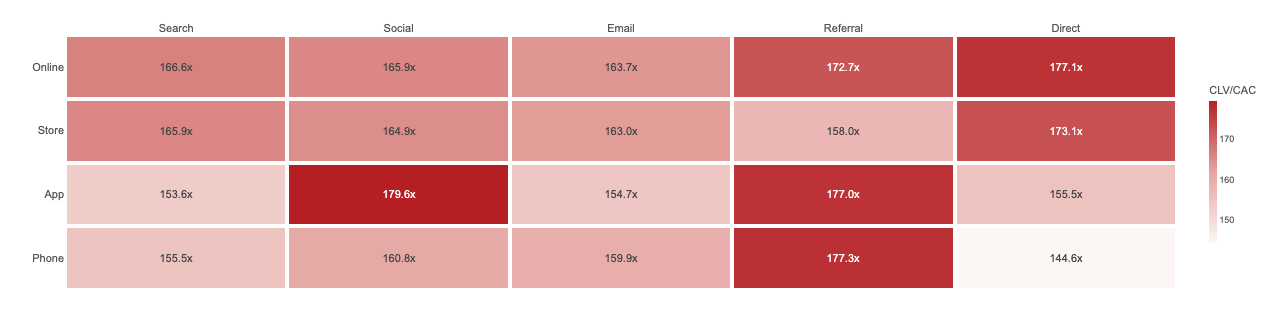

# Executive Summary

**Acquisition scale.** Search leads customer volume with 15,034 customers (30.1% of the dataset).

**Acquisition cost.** Referral has the lowest mean CAC (104.23 source units).

**Estimated value.** Direct has the highest median estimated CLV (14,988.50 source units); Direct has the highest median customer-level CLV/CAC (171.31x).

## First-purchase consistency

- **App:** Social leads median CLV/CAC at 179.57x across a subgroup of 7,451 customers.

- **Online:** Direct leads median CLV/CAC at 177.11x across a subgroup of 25,306 customers.

- **Phone:** Referral leads median CLV/CAC at 177.28x across a subgroup of 2,393 customers.

- **Store:** Direct leads median CLV/CAC at 173.13x across a subgroup of 14,850 customers.

The CLV/CAC leader changes across first-purchase subgroups; the overall leader does not represent every purchase context.

## Decision implications

Use separate lenses for acquisition scale, cost, and estimated value. Review channels within the relevant first-purchase context before prioritizing further investigation. These comparisons do not estimate incremental marketing returns or an optimal budget allocation.

## Method and limitations

One row per unique customer. Counts retain all records; financial metrics use valid non-negative values. CLV/CAC is calculated per customer with positive CAC before taking the group median. Valid sample counts accompany each metric. Cross-tab customer shares are normalized within each first-purchase subgroup. CLV is estimated, currency units are unverified, subgroup sizes differ, and channel differences are descriptive. Date anomalies are logged without removing records; no date-based or active-customer filter is applied.

In [12]:
import channel_app
importlib.reload(channel_app)
from channel_app import export_figures

figures = channel_app.build_views(df, df, "__ALL__")
for name, figure in figures.items():
    display(figure)

display(Markdown(executive_summary(df, channel_summary, channel_by_first)))

## 4. Interactive Executive Dashboard
The first-purchase filter updates the KPI cards, findings, four charts and performance table together. `Customers in Scope` refers to selected records; no active-customer definition is inferred.

**Team integration.** Reuse `channel_layout(df)` and `register_channel_callbacks(app, df)` in the team's Dash app. Include `channel_app.CSS` once in its stylesheet or index template. All component IDs use the `b-` prefix. Integrate C's segment view in the shared app after its interface is available.

**Automation entry point.** `python channel_analysis.py --input data/customer_clean.csv --output reports/channel`

**Standalone dashboard.** `python channel_app.py --input data/customer_clean.csv`

Dash supports local Jupyter execution through `jupyter_mode="external"` ([official documentation](https://dash.plotly.com/dash-in-jupyter)). The server cell is excluded from automated notebook execution; run it interactively. Use a different port if 8050 is occupied.


In [13]:
app = channel_app.build_app(DATA_PATH)
app.run(jupyter_mode="external", port=8050, debug=False)

Dash app running on http://127.0.0.1:8050/
